# Module 4 — Supervised Learning: Regression


### Setup

In [117]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
import seaborn as sns
warnings.filterwarnings("ignore")
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.impute import KNNImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures, FunctionTransformer
from sklearn.linear_model import LinearRegression, Ridge, RidgeCV, Lasso, LassoCV
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance, PartialDependenceDisplay


REPO = "https://raw.githubusercontent.com/sparks5969/course-advanced-data-analysis/main"
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

---
### Where we are

| | Module 3 | Module 4 |
|---|---|---|
| the label | a category: goal / no goal, default / repay | **a number**: a price, a fare, a wage |
| the model outputs | a probability, then a decision | **the number itself** |
| the mistake | wrong box in the confusion matrix | **a distance**: how far off, in dollars |
| what we judge | precision, recall, cost | **the size of the typical miss** |


### The data: California housing, 1990

One row = one census block group (a neighbourhood of ~1,500 people). The label is the **median house value** in that neighbourhood.

In [118]:
housing = pd.read_csv(f"{REPO}/california_housing_gaps.csv")
print(housing.shape)
housing.head()

(20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.230,37.880,41.000,880.000,129.000,322.000,126.000,8.325,"452,600.000",NEAR BAY
1,-122.220,37.860,21.000,"7,099.000","1,106.000","2,401.000","1,138.000",8.301,"358,500.000",NEAR BAY
2,-122.240,37.850,52.000,"1,467.000",190.000,496.000,177.000,7.257,"352,100.000",NEAR BAY
3,-122.250,37.850,52.000,"1,274.000",235.000,558.000,219.000,5.643,"341,300.000",NEAR BAY
4,-122.250,37.850,52.000,"1,627.000",280.000,565.000,259.000,3.846,"342,200.000",NEAR BAY


### Exploratory Data Analysis (A very brief version)

In [119]:
# 1. Show missing values
print("=== Missing Values ===")
print(housing.isnull().sum())

# 2. Explore 'ocean_proximity' categories
print("\n=== 'ocean_proximity' Category Distribution ===")
print(housing['ocean_proximity'].value_counts())

# 3. Numeric variables summary metrics
print("\n=== Summary Statistics for Numeric Variables ===")
print(housing.describe())

=== Missing Values ===
longitude                0
latitude                 0
housing_median_age    1083
total_rooms              0
total_bedrooms         604
population             975
households               0
median_income         1343
median_house_value       0
ocean_proximity          0
dtype: int64

=== 'ocean_proximity' Category Distribution ===
ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

=== Summary Statistics for Numeric Variables ===
       longitude   latitude  housing_median_age  total_rooms  total_bedrooms  \
count 20,640.000 20,640.000          19,557.000   20,640.000      20,036.000   
mean    -119.570     35.632              28.639    2,635.763         538.412   
std        2.004      2.136              12.589    2,181.615         422.679   
min     -124.350     32.540               1.000        2.000           1.000   
25%     -121.800     33.930              18.000    1,447.7

In [120]:
print(housing.dtypes.to_string(), "\n")
print("missing values:\n", housing.isna().sum()[housing.isna().sum() > 0].to_string(), "\n")
print(housing.ocean_proximity.value_counts().to_string(), "\n")
print("skewness:\n", housing.select_dtypes("number").skew().round(2).to_string(), "\n")
print(f"price capped: {(housing.median_house_value >= 500_000).sum()} rows at $500,001")

longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
ocean_proximity        object 

missing values:
 housing_median_age    1083
total_bedrooms         604
population             975
median_income         1343 

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5 

skewness:
 longitude            -0.300
latitude              0.470
housing_median_age    0.060
total_rooms           4.150
total_bedrooms        3.470
population            5.350
households            3.410
median_income         1.640
median_house_value    0.980 

price capped: 992 rows at $500,001


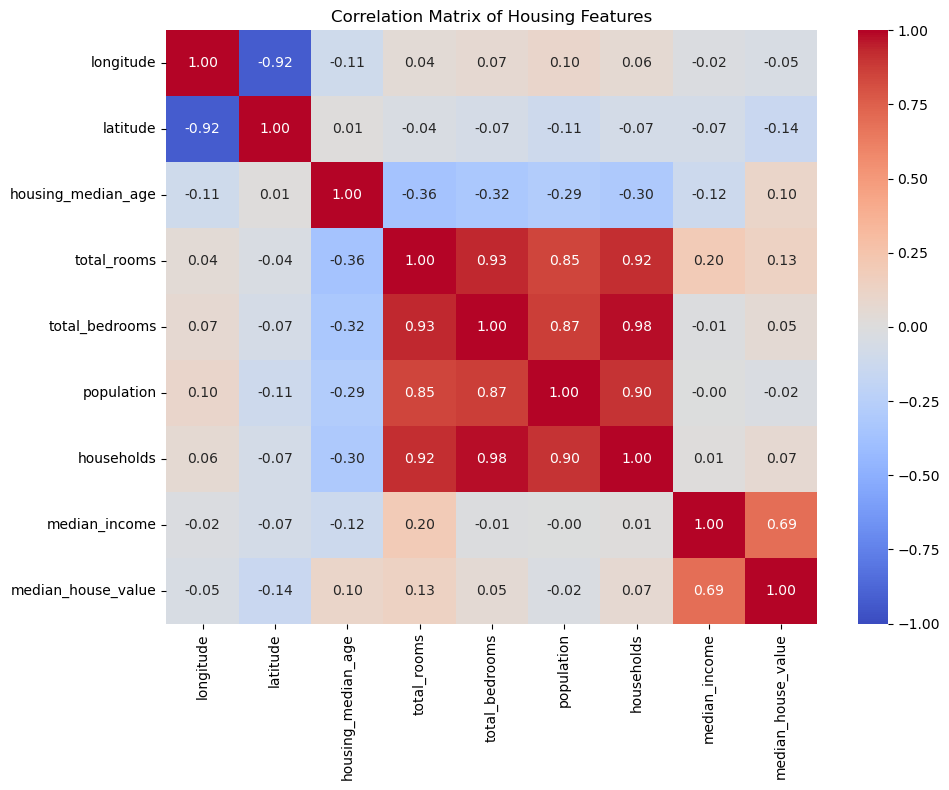

In [121]:
# Calculate the correlation matrix for numeric features
corr_matrix = housing.select_dtypes("number").corr()

# Create a heatmap visualization
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix of Housing Features")
plt.tight_layout()
plt.show()

### Some insights from the VERY BRIEF exploratory data analysis

- **Four columns have gaps** — `median_income`, `housing_median_age`, `population`, `total_bedrooms` — and about one row in six has at least one. A linear model refuses to fit with a single missing value, so filling them is step one. *How* to fill them is a decision, made after the split by looking at who is missing.
- **`ocean_proximity` is text** with five categories. One of them, ISLAND, has five rows. We need to encode it — and remember that a category the training data never saw can still turn up in the test set.
- **Four count columns are heavily skewed** (`total_rooms`, `population`, … skew 3–5). They are totals for a neighbourhood, not per-house figures. Ratios (rooms per household) are what economists would reach for.
- **The target is capped at \$500,001**, 992 neighbourhoods sit exactly there. The data cannot tell a $500k neighbourhood from a $2M one. Keep it in mind when the model "misses" at the top.
- **`median_income`** and **`median_house_value`** are highly correlated


### The target: should we predict price, or log price?

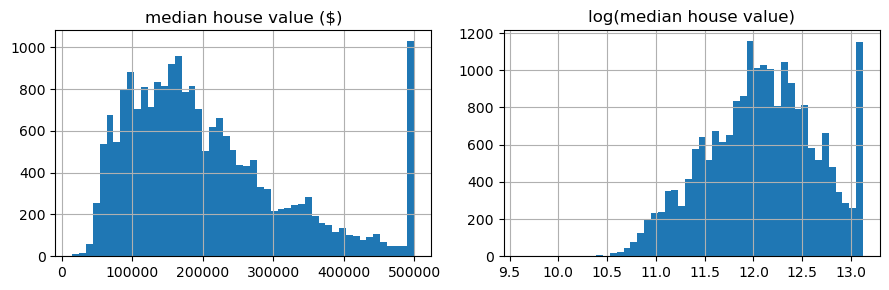

In [122]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
housing.median_house_value.hist(bins=50, ax=ax[0]); ax[0].set_title("median house value ($)")
np.log(housing.median_house_value).hist(bins=50, ax=ax[1]); ax[1].set_title("log(median house value)")
plt.tight_layout(); plt.show()

Prices are right-skewed with a wall at the cap. A linear model fit to raw dollars spends its effort on the expensive tail; fit to **log price** it works in *percent* terms, and a 10% miss costs the same whether the house is cheap or dear. We will try both — and convert back to dollars before we judge, because MAE in log units means nothing to anyone.

### Partition

80 / 20, before we learn anything. Validation inside the 80 comes from cross-validation when we need it.

In [123]:
X = housing.drop(columns="median_house_value")
y = housing.median_house_value
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(len(X_train), "train /", len(X_test), "test   | median price in train:", f"${y_train.median():,.0f}")

16512 train / 4128 test   | median price in train: $179,850


### Preprocessing — what has to happen before any model sees the data

**The rule that governs all of it:** every step is *learned from the training split only* and then *applied* to the test split. A median, a list of categories, a mean and standard deviation — each is estimated from data, so each can leak. That is why the steps live inside a pipeline rather than in a cell you run on the whole table.

| step | the problem | the usual repair | where this notebook does it |
|---|---|---|---|
| **Domain features** | the columns describe the wrong thing | build ratios and interactions an economist would ask for | here — rooms per household, bedrooms per room, people per household |
| **Missing values** | a linear model refuses to fit with one blank cell | fill with the training median (numeric) or a "missing" category; sometimes add a flag | next: see who is missing, then decide column by column |
| **Categories → numbers** | text columns have no arithmetic | one-hot encoding; decide what to do with categories the model has never seen | here — `ocean_proximity`, incl. ISLAND with 5 rows |
| **Skewed features** | a few huge values dominate a line | log the heavy-tailed columns | section "Adjusting skewness" |
| **The target** | the label can be skewed or capped too | predict log price; know where the cap is | section "The target: price or log price?" |
| **Scale** | penalties and distances compare coefficients across units | standardise numeric columns | section "Scale first, or the penalty is unfair" — not needed for OLS, never needed for trees |



Which steps a model needs is part of what defines the model.


### See the gaps before filling them

*Why* a value is missing decides how it may be filled. Three cases:

- **MCAR — missing completely at random.** The gap has nothing to do with anything, observed or not. Any fill is unbiased; the median is the cheapest.
- **MAR — missing at random *given what we observe*.** The chance of a gap depends on other columns. One overall median then biases the filled rows toward the centre of the whole table. The fill must condition on those columns: nearest neighbours, or a regression on them.
- **MNAR — missing *because of* the value itself.** High earners decline to report income. No fill recovers the truth. Add a 0/1 flag so the model can at least use the fact of the gap, and say so in the write-up.

The data can tell the first two apart: compare the rows that have a gap with the rows that do not, on every other column. If nothing differs, the gap looks random. If something differs, that something predicts the gap, and the fill must use it. MNAR cannot be seen in any table; it is known only from how the data were collected.

This is already modelling, so look at the training split only.


In [124]:
train = X_train                                      # the training split only
gaps = train.isna().sum(); gaps = gaps[gaps > 0]
print("columns with gaps:"); print(gaps.to_string())
print(f"\nrows with at least one gap: {train.isna().any(axis=1).mean():.1%}")

def who_is_missing(col):
    """Rows WITH a gap in `col` vs rows WITHOUT, compared on every other column. ratio = with / without."""
    m = train[col].isna()
    others = train.drop(columns=col).select_dtypes("number")
    out = pd.DataFrame({"with gap": others[m].median(), "without": others[~m].median()})
    out.loc["share INLAND"] = [train.ocean_proximity[m].eq("INLAND").mean(), train.ocean_proximity[~m].eq("INLAND").mean()]
    out["ratio"] = out["with gap"] / out["without"]
    return out

gap_table = pd.concat({col: who_is_missing(col) for col in gaps.index}).round(2)   # one block per column with gaps
gap_table


columns with gaps:
housing_median_age     858
total_bedrooms         326
population             774
median_income         1070

rows with at least one gap: 17.2%


with gap   without  ratio
housing_median_age longitude           -118.620  -118.500  1.000
                   latitude              34.380    34.260  1.000
                   total_rooms        2,112.500 2,131.000  0.990
                   total_bedrooms       435.500   437.000  1.000
                   population         1,149.000 1,143.000  1.010
                   households           404.500   411.000  0.980
                   median_income          3.520     3.570  0.990
                   share INLAND           0.310     0.320  0.990
total_bedrooms     longitude           -118.460  -118.510  1.000
                   latitude              34.260    34.260  1.000
                   housing_median_age    27.000    29.000  0.930
                   total_rooms        2,145.500 2,129.000  1.010
                   population         1,132.500 1,144.000  0.990
                   households           414.000   410.000  1.010
                   median_income          3.530     3.570  0.990
                   share INLAND           0.350     0.320  1.110
population         longitude           -118.520  -118.510  1.000
                   latitude              34.260    34.260  1.000
                   housing_median_age    22.000    29.000  0.760
                   total_rooms        3,725.500 2,080.000  1.790
                   total_bedrooms       794.000   425.000  1.870
                   households           743.000   400.000  1.860
                   median_income          3.530     3.570  0.990
                   share INLAND           0.320     0.320  1.000
median_income      longitude           -119.570  -118.480  1.010
                   latitude              36.330    34.240  1.060
                   housing_median_age    30.000    29.000  1.030
                   total_rooms        2,023.000 2,143.000  0.940
                   total_bedrooms       404.000   439.000  0.920
                   population         1,055.000 1,150.000  0.920
                   households           377.000   413.000  0.910
                   share INLAND           0.620     0.300  2.080

### Read the table, then decide

Filling a gap is two questions, answered by two tables we already have.

**1. Is the gap itself predictable?** (the table above) Read the **ratio** column. Near 1 on every line: the rows with a gap look like everyone else, so the gap is MCAR and *any* fill is unbiased. Far from 1 on some line: that column predicts the gap, so the gap is MAR and the fill *must* condition on that column. The ratio measures size, not significance — with sixteen thousand rows almost any difference is "significant"; the question is whether it is big enough to bias a fill.

**2. Is the missing value predictable?** (the correlation matrix in the EDA) If other columns track the value closely, a fill built from them is close to the truth. If nothing does, the median is as good as any fill can be.

| column | 1 · gap predictable? | 2 · value predictable? | fill |
|---|---|---|---|
| `housing_median_age` | no — all ratios ≈ 1 → MCAR | no — strongest correlation 0.36 | **median** |
| `total_bedrooms` | no — all ratios ≈ 1 → MCAR | yes — 0.98 with households, 0.93 with rooms | **KNN on the counts**: the median would be unbiased, but the neighbours' fill is far closer to the truth |
| `population` | yes — rooms and households at ratio 1.8–1.9 → MAR, driven by size | yes — 0.90 with households, 0.85 with rooms | **KNN on the counts**: required by question 1, accurate by question 2 |
| `median_income` | yes — share INLAND at ratio 2.1, two degrees further north → MAR, driven by region | not by any single column (all below 0.2) — but income clusters on the map: neighbouring block groups earn alike | **KNN on longitude and latitude**: condition on region by taking the five nearest neighbourhoods |

Two KNN groups and one median. The next cell builds exactly this. An AI assistant can write that cell in a second; it cannot answer question 1 for you, because the mechanism is a claim about how the data were collected, not about the numbers.


### Preprocessing: the machinery

The cell below turns the raw data table into a numeric matrix a model can read. Three steps run one after the other. Each is a **transformer**: an object that *fits* something on the training split when you call `fit`, and *applies* it to any table when you call `transform`.

**Step 1 — `ColumnTransformer` for imputation: the decisions from the table above.**
A `ColumnTransformer` does no computation of its own. It splits the columns into groups, hands each group to a separate tool, and puts the results back side by side. Each group is the subset of columns that may be used to fill each other: every column in it is both a possible target and a possible predictor, and columns in different groups never meet. `remainder="passthrough"` keeps the text column as it is; `set_output(transform="pandas")` keeps the column names so the next step can use them.

| group | columns | tool | what `fit` estimates on the training split | what `transform` does |
|---|---|---|---|---|
| knn_set1 | `total_rooms`, `total_bedrooms`, `population`, `households` | `KNNImputer` | keeps the training rows as a lookup table | a gap is filled with the average of the 5 training rows closest on the other three counts |
| knn_set2 | `longitude`, `latitude`, `median_income` | `KNNImputer` | same | a gap in income is filled from the 5 nearest neighbourhoods on the map |
| median_set1 | `housing_median_age` | `SimpleImputer(median)` | one median | a gap is filled with it |

**Step 2 — `FunctionTransformer(add_ratios)`: add columns.**
Input: the imputed table. Output: the same table with three new columns (rooms per household, bedrooms per room, people per household), computed from columns that are already there. `FunctionTransformer` is only a wrapper that lets our own function sit inside the pipeline. There is nothing to "fit": a row's ratios depend only on that row. Ratios come *after* imputation so that every ratio is built from a complete row.

**Step 3 — `ColumnTransformer` for encoding.**
Numeric columns pass through unchanged; `ocean_proximity` goes to `OneHotEncoder`, whose `fit` records the list of categories and whose `transform` makes each one its own 0/1 column (a category not seen in training becomes all zeros instead of an error). Output: one numeric matrix, 16 columns wide (11 numeric + 5 one-hot), with no gaps and no column names.

**`make_pipeline`** chains the three steps, and later the model, into one object. `fit` on the pipeline fits step 1, then 2, then 3, then the model, each on the training split and in that order. `predict` runs the same chain on the test split without refitting anything. That is the mechanism behind the rule from the overview: everything is fitted on train and only applied on test.


In [125]:
# step 1: fill the gaps — one tool per column group, as decided above
KNN_SET1    = ["total_rooms", "total_bedrooms", "population", "households"]
KNN_SET2    = ["longitude", "latitude", "median_income"]
MEDIAN_SET1 = ["housing_median_age"]

impute = ColumnTransformer([
    ("knn_set1",    KNNImputer(n_neighbors=5),        KNN_SET1),      # population (MAR, driven by size) and bedrooms: both predictable from the other counts
    ("knn_set2",    KNNImputer(n_neighbors=5),        KNN_SET2),      # income (MAR, driven by region): the 5 nearest neighbourhoods on the map
    ("median_set1", SimpleImputer(strategy="median"), MEDIAN_SET1),   # age (MCAR): any fill is unbiased, the median is enough
], remainder="passthrough", verbose_feature_names_out=False).set_output(transform="pandas")   # keep ocean_proximity, keep column names


# step 2: add the ratio features — nothing to fit
def add_ratios(d):
    d = d.copy()
    d["rooms_per_household"]  = d.total_rooms / d.households
    d["bedrooms_per_room"]    = d.total_bedrooms / d.total_rooms
    d["people_per_household"] = d.population / d.households
    return d


NUM = KNN_SET1 + KNN_SET2 + MEDIAN_SET1 + ["rooms_per_household", "bedrooms_per_room", "people_per_household"]

# step 3: encode the text column; numeric columns pass through
CAT    = ["ocean_proximity"]
encode = ColumnTransformer([
    ("num", "passthrough",                          NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT),
])

preprocess = make_pipeline(impute, FunctionTransformer(add_ratios), encode) # this is the final preprocessor, ready to be fit on the training split and applied to any new data

# the next line is an example of how it works.
# Xt = preprocess.fit_transform(X_train)        # fit = estimate on the training split; transform = apply
# print("model-ready matrix:", Xt.shape, "| any NaN left?", np.isnan(Xt).any())


In [126]:
results = pd.DataFrame(columns=["target", "test MAE ($)", "test RMSE ($)", "test R²", "train R²"])
predictions = {}                                            # test-set predictions, kept by name, for the plots below

def train_and_test(X_train, y_train, X_test, y_test, prep, model, log_target=True):
    # prep: the preprocessing recipe | model: any scikit-learn regressor, not yet fitted | log_target: fit on log(price)
    # ---- TRAIN: everything here is fitted on the training split only
    y_fit = np.log(y_train) if log_target else y_train     # the target the model actually sees
    Xtr = prep.fit_transform(X_train)                       # fit the recipe (imputers, encoder, ...) on X_train, and transform X_train
    model.fit(Xtr, y_fit)                                   # fit the model on the model-ready matrix
    # ---- TEST: apply what was fitted; nothing is refitted here
    Xte = prep.transform(X_test)                            # same medians, neighbours, categories — applied to rows never seen
    p_train, p_test = model.predict(Xtr), model.predict(Xte)
    if log_target:
        p_train, p_test = np.exp(p_train), np.exp(p_test)   # back to dollars
    return make_pipeline(prep, model), p_train, p_test      # the fitted recipe + model, chained; predictions for both splits

def report(name, model, prep, log_target=True):
    # train and test on the notebook's split, then RECORD one row under `name`
    fitted, p_train, p_test = train_and_test(X_train, y_train, X_test, y_test, prep, model, log_target)
    results.loc[name] = ["log price" if log_target else "price",
                         mean_absolute_error(y_test, p_test),                       # typical miss on unseen data, in dollars
                         np.sqrt(mean_squared_error(y_test, p_test)),               # same, but large misses count more
                         r2_score(y_test, p_test), r2_score(y_train, p_train)]      # test vs train R²: the gap is overfitting
    predictions[name] = p_test
    return fitted

def plot_fit(*names):
    # observed vs predicted price on the test split, one panel per recorded model; the 45° line is a perfect prediction
    fig, axes = plt.subplots(1, len(names), figsize=(4.2 * len(names), 4), squeeze=False)
    for ax, name in zip(axes[0], names):
        ax.scatter(y_test / 1000, predictions[name] / 1000, s=4, alpha=0.25)
        lim = (0, 1.05 * max(y_test.max(), predictions[name].max()) / 1000)
        ax.plot(lim, lim, color="gray", ls="--", lw=1)                               # 45° line
        ax.set(xlim=lim, ylim=lim, xlabel="observed price ($000)", ylabel="predicted price ($000)",
               title=f"{name}\ntest MAE ${results.loc[name, 'test MAE ($)']:,.0f}")
    plt.tight_layout(); plt.show()

def show(table=None):
    out = (results if table is None else table).copy()
    for c in out.columns:
        if "$" in c: out[c] = out[c].map("{:,.0f}".format)
        elif "R²" in c: out[c] = out[c].map("{:.3f}".format)
    return out


### Evaluating Results

Three numbers you will see everywhere. For a test set of $n$ houses with true prices $y_i$ and predictions $\hat y_i$:

| metric | formula | reads as |
|---|---|---|
| **MAE** — mean absolute error | $\frac{1}{n}\sum \lvert y_i - \hat y_i \rvert$ | *the typical miss, in dollars.* Robust to a few huge misses |
| **RMSE** — root mean squared error | $\sqrt{\frac{1}{n}\sum (y_i - \hat y_i)^2}$ | *also in dollars,* but big misses are punished more. Always ≥ MAE |
| **R²** | $1 - \frac{\sum (y_i-\hat y_i)^2}{\sum (y_i-\bar y)^2}$ | *share of the variation explained.* Unit-free; 0 = predicting the mean, 1 = perfect |

**We will lead with MAE in dollars.** A lender, a buyer, an airline — nobody acts on an R². They act on "you'll be off by about $45,000."

Keep in mind that regression has no threshold. There is no decision to tune after the fact — the prediction *is* the output. The judgment moves upstream, into the features and the model.

### Ordinary least squares

Row one. Twice: on raw price and on log price.

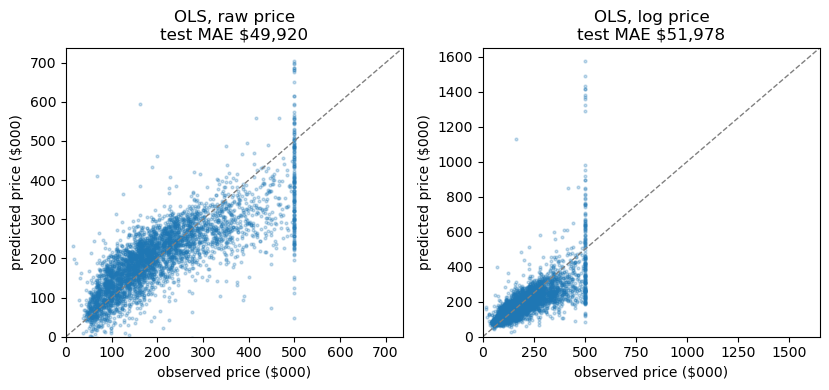

,target,test MAE ($),test RMSE ($),test R²,train R²
"OLS, raw price",price,"49,920","69,436",0.632,0.647
"OLS, log price",log price,"51,978","88,332",0.405,0.417


In [127]:
ols_raw = report("OLS, raw price", LinearRegression(), prep=preprocess, log_target=False)
ols_log = report("OLS, log price", LinearRegression(), prep=preprocess)
plot_fit("OLS, raw price", "OLS, log price")
show()


### Reading the first rows

- The typical miss is about **$50,000 on a $180,000 house** — a 28% error. Serviceable, not impressive.
- **Log price made it worse.** Surprising? Think about the shape: log price against a *raw* population count says that going from 300 people to 600 moves price by the same amount as going from 30,000 to 30,300. That is the wrong shape, and a few extreme neighbourhoods produce wild predictions once we exponentiate.
- Train R² and test R² are close: OLS with 16 features and 16,000 rows is not overfitting. The problem is the *shape*.

### Adjusting skewness: log the features too

The four count columns and the ratios are skewed by a factor of 3–5. Logging them *and* the target gives the economist's favourite model — **log-log**, where every coefficient is an elasticity: a 1% change in income moves price by β%. Same shape on both sides of the equation.

The new recipe gets its own name, `preprocess_log`, and from here on every call passes it. (Trees won't care — a log is a monotone relabelling of the cut points — but it costs nothing.)

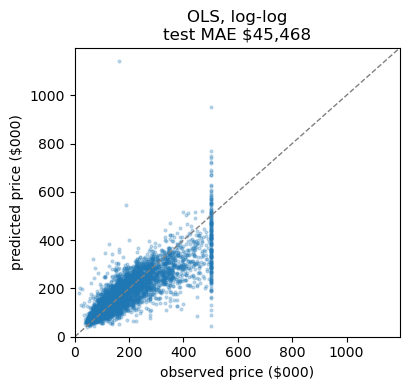

,target,test MAE ($),test RMSE ($),test R²,train R²
"OLS, raw price",price,"49,920","69,436",0.632,0.647
"OLS, log price",log price,"51,978","88,332",0.405,0.417
"OLS, log-log",log price,"45,468","68,146",0.646,0.657


In [128]:
SKEWED = ["total_rooms", "total_bedrooms", "population", "households", "median_income",
          "rooms_per_household", "people_per_household"]

def log_skewed(d):
    d = d.copy()
    for c in SKEWED:
        d[c] = np.log1p(d[c])
    return d

preprocess_log = make_pipeline(                       # a new recipe, with a new name
    impute,                                           # the same imputation decisions as before
    FunctionTransformer(add_ratios),
    FunctionTransformer(log_skewed),                  # the new step
    ColumnTransformer([
        ("num", "passthrough", NUM),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT),
    ]),
)
ols = report("OLS, log-log", LinearRegression(), prep=preprocess_log)
plot_fit("OLS, log-log")
show()


### The shape was the problem

Log on both sides: the typical miss drops from about $50,000 to about **$45,000**, and R² is back where it was. The "adjust skewness" step is not a ritual — it is choosing a functional form, and a linear model lives or dies by it.

### More features: bending the line

OLS is a straight line in every feature. One way to bend it: **polynomial features** — every square and every pairwise product of the numeric columns. Eleven columns at degree 2 become 77: the 11 originals, their 11 squares, and 55 products. Same recipe as before with one extra step, and the same OLS on top. Does the bend help?


columns the model sees: 82 = 77 polynomial terms + 5 one-hot


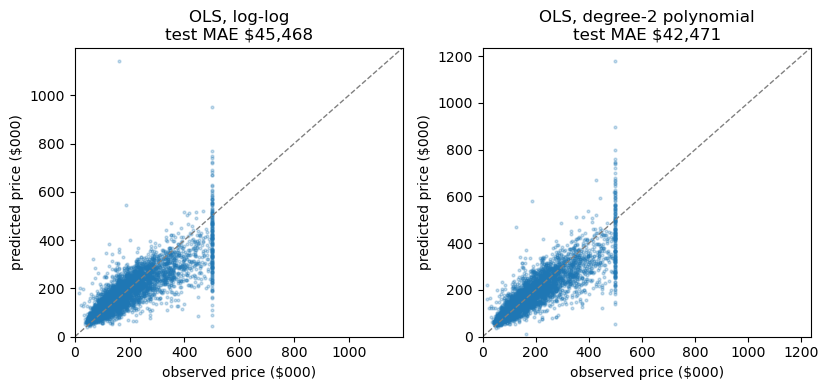

,target,test MAE ($),test RMSE ($),test R²,train R²
"OLS, raw price",price,"49,920","69,436",0.632,0.647
"OLS, log price",log price,"51,978","88,332",0.405,0.417
"OLS, log-log",log price,"45,468","68,146",0.646,0.657
"OLS, degree-2 polynomial",log price,"42,471","63,662",0.691,0.710


In [129]:
poly_prep = make_pipeline(
    impute,
    FunctionTransformer(add_ratios),
    FunctionTransformer(log_skewed),
    ColumnTransformer([("num", make_pipeline(StandardScaler(), PolynomialFeatures(degree=2, include_bias=False)), NUM),   # scale first: squares of raw counts would be astronomical
                       ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)]),
)
poly = report("OLS, degree-2 polynomial", LinearRegression(), prep=poly_prep)
print("columns the model sees:", poly[:-1].transform(X_train).shape[1], "= 77 polynomial terms + 5 one-hot")
plot_fit("OLS, log-log", "OLS, degree-2 polynomial")
show()


### What just happened

- The typical miss drops from about $45,000 to about **$42,500**, and test R² from 0.65 to 0.69. Bending the line helps — a little.
- Train R² 0.71 against test R² 0.69.
- What it costs: 77 coefficients instead of 11, and they are hard to interpret. The effect of income is now spread over its square and ten products.

So more features buy accuracy slowly, at the price of interpretability, and the bill grows with every degree. A model with hundreds of features needs a way to keep the useful ones and damp the rest. That is the next tool.


### Lasso and Ridge — a penalty on the coefficients

OLS minimises the squared error. Ridge and lasso minimise the squared error **plus a price for large coefficients:**

$$\text{ridge:}\quad \sum_i (y_i - \mathbf{x}_i\boldsymbol\beta)^2 \;+\; \lambda \sum_j \beta_j^2
\qquad\qquad
\text{lasso:}\quad \sum_i (y_i - \mathbf{x}_i\boldsymbol\beta)^2 \;+\; \lambda \sum_j \lvert\beta_j\rvert$$

- $\lambda = 0$ is OLS. Larger $\lambda$ shrinks every coefficient toward zero.
- **Ridge shrinks.** Coefficients get small, never exactly zero.
- **Lasso selects.** The absolute-value penalty pushes weak coefficients *exactly* to zero — the model drops features by itself.
- **Elastic net** mixes the two penalties. One slider, both behaviours.


### Scale first, or the penalty is unfair

The penalty charges every coefficient the same price. But a coefficient's size depends on its feature's units: `median_income` runs 0.5–15, `population` runs into the thousands. Unscaled, the penalty crushes whichever feature happens to have big numbers.

**Standardise every numeric feature before penalising.** Trees won't care about this. Penalised linear models care about nothing else.

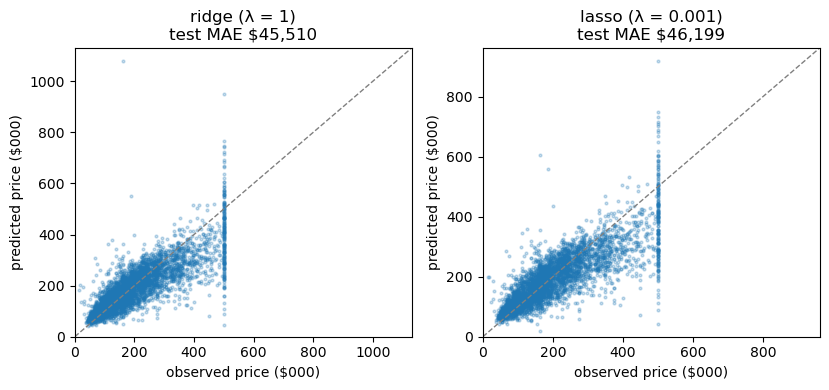

,target,test MAE ($),test RMSE ($),test R²,train R²
"OLS, raw price",price,"49,920","69,436",0.632,0.647
"OLS, log price",log price,"51,978","88,332",0.405,0.417
"OLS, log-log",log price,"45,468","68,146",0.646,0.657
"OLS, degree-2 polynomial",log price,"42,471","63,662",0.691,0.710
ridge (λ = 1),log price,"45,510","68,002",0.647,0.664
lasso (λ = 0.001),log price,"46,199","67,931",0.648,0.663


In [130]:
scaled_prep = make_pipeline(
    impute,
    FunctionTransformer(add_ratios),
    FunctionTransformer(log_skewed),
    ColumnTransformer([("num", StandardScaler(), NUM),
                       ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)]),
)
ridge = report("ridge (λ = 1)",  Ridge(alpha=1.0),  prep=scaled_prep)
lasso = report("lasso (λ = 0.001)", Lasso(alpha=0.001), prep=scaled_prep)
plot_fit("ridge (λ = 1)", "lasso (λ = 0.001)")
show()


### Lasso as a selector

Which features survived? Read the coefficients (on standardised features, so they are comparable).

5 of 16 coefficients set exactly to zero: ['total_rooms', 'total_bedrooms', 'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN']


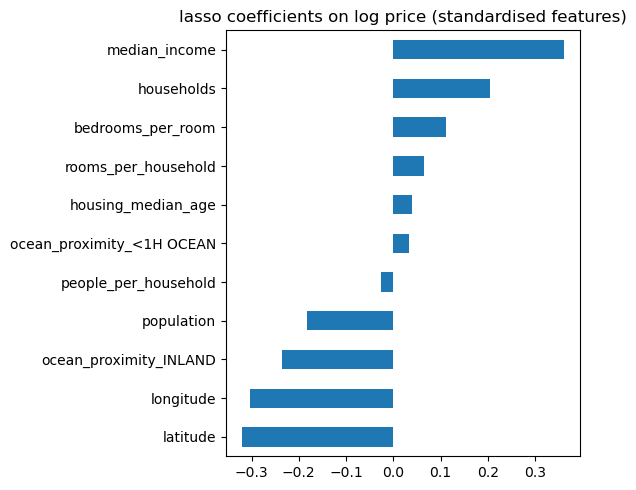

In [131]:
feat_names = NUM + list(lasso[0][-1].named_transformers_["cat"].get_feature_names_out(CAT))
coef = pd.Series(lasso[-1].coef_, index=feat_names).sort_values()
print(f"{(coef == 0).sum()} of {len(coef)} coefficients set exactly to zero:", list(coef[coef == 0].index))
coef[coef != 0].plot.barh(figsize=(6, 5), title="lasso coefficients on log price (standardised features)")
plt.tight_layout(); plt.show()

### Where Part I leaves us

Four linear rows, all within a few thousand dollars of each other. The polynomial terms bought about $3,000; the penalties bought nothing here, because with 16,000 rows and 16 features the data's own opinion is already precise. Every linear row misses by **$42,000–46,000**.



---
## Tree-based Models


### One tree

A regression tree asks a sequence of yes/no questions about the features and predicts the **average price of the training houses that landed in the same leaf**. No line, no coefficients, no units — a tree never needs scaling, and it finds interactions by itself.

*(deck slides 60–69: how a split is chosen — try every feature and every cut point, keep the one that reduces squared error most)*

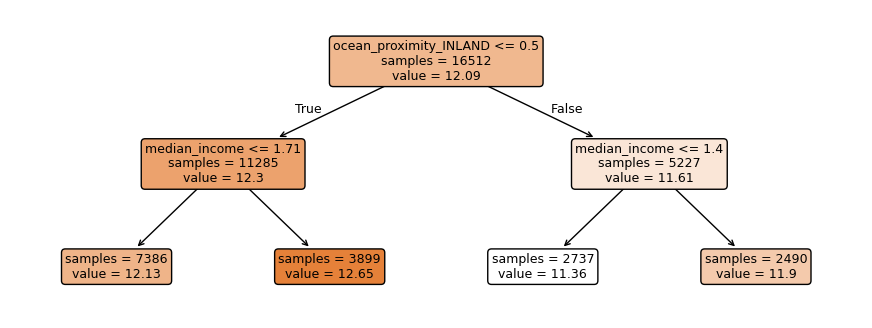

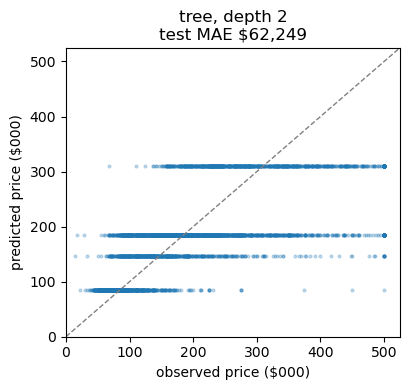

In [132]:
tree2 = report("tree, depth 2", DecisionTreeRegressor(max_depth=2, random_state=0), prep=preprocess_log)
fig, ax = plt.subplots(figsize=(11, 4))
plot_tree(tree2[-1], feature_names=feat_names, filled=True, rounded=True, fontsize=9, ax=ax,
          precision=2, impurity=False)
plt.show()
plot_fit("tree, depth 2")


### Read the tree

The first question the tree asks is about **income**. The second, on each side, is about income again or about **location**. Two questions, four leaves, four predicted (log) prices. That is a model.

Depth 2 is a toy. Let the tree grow until every leaf is pure.

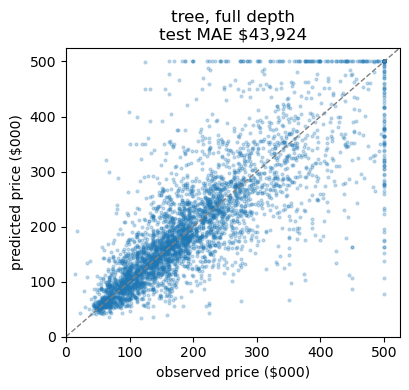

,target,test MAE ($),test RMSE ($),test R²,train R²
"OLS, raw price",price,"49,920","69,436",0.632,0.647
"OLS, log price",log price,"51,978","88,332",0.405,0.417
"OLS, log-log",log price,"45,468","68,146",0.646,0.657
"OLS, degree-2 polynomial",log price,"42,471","63,662",0.691,0.710
ridge (λ = 1),log price,"45,510","68,002",0.647,0.664
lasso (λ = 0.001),log price,"46,199","67,931",0.648,0.663
"tree, depth 2",log price,"62,249","87,465",0.416,0.427
"tree, full depth",log price,"43,924","69,430",0.632,1.000
"tree, depth 10",log price,"39,263","60,998",0.716,0.828
random forest (200 trees),log price,"31,751","51,123",0.801,0.968


In [143]:
tree_full = report("tree, full depth", DecisionTreeRegressor(random_state=0), prep=preprocess_log)
plot_fit("tree, full depth")
show()


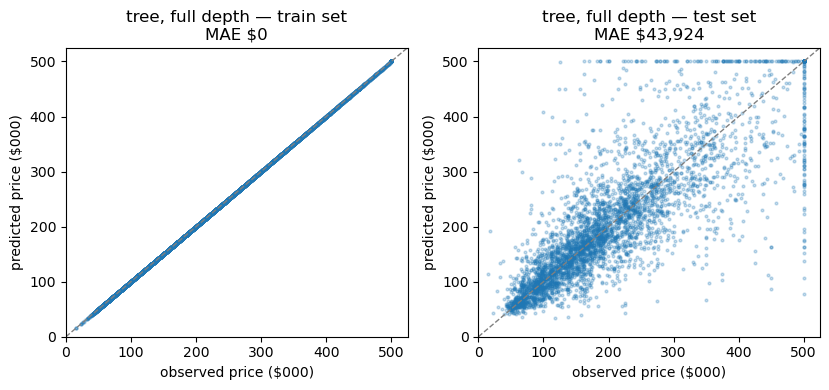

,target,test MAE ($),test RMSE ($),test R²,train R²
"OLS, raw price",price,"49,920","69,436",0.632,0.647
"OLS, log price",log price,"51,978","88,332",0.405,0.417
"OLS, log-log",log price,"45,468","68,146",0.646,0.657
"OLS, degree-2 polynomial",log price,"42,471","63,662",0.691,0.710
ridge (λ = 1),log price,"45,510","68,002",0.647,0.664
lasso (λ = 0.001),log price,"46,199","67,931",0.648,0.663
"tree, depth 2",log price,"62,249","87,465",0.416,0.427
"tree, full depth",log price,"43,924","69,430",0.632,1.000


In [134]:
p_train = np.exp(tree_full.predict(X_train))                      # the fitted recipe + tree, applied to the training rows
fig, axes = plt.subplots(1, 2, figsize=(8.4, 4))
for ax, (split, y_obs, p) in zip(axes, [("train", y_train, p_train), ("test", y_test, predictions["tree, full depth"])]):
    ax.scatter(y_obs / 1000, p / 1000, s=4, alpha=0.25)
    lim = (0, 1.05 * max(y_obs.max(), p.max()) / 1000)
    ax.plot(lim, lim, color="gray", ls="--", lw=1)                 # 45° line = perfect prediction
    ax.set(xlim=lim, ylim=lim, xlabel="observed price ($000)", ylabel="predicted price ($000)",
           title=f"tree, full depth — {split} set\nMAE ${mean_absolute_error(y_obs, p):,.0f}")
plt.tight_layout(); plt.show()
show()

### The tree memorised the training set

Train R² = 1.000. Every training house sits alone in its own leaf, predicted perfectly. Test MAE: **worse than OLS.** The full-depth tree is Module 2's perfect fit, again.

Depth is a dial. Turn it.

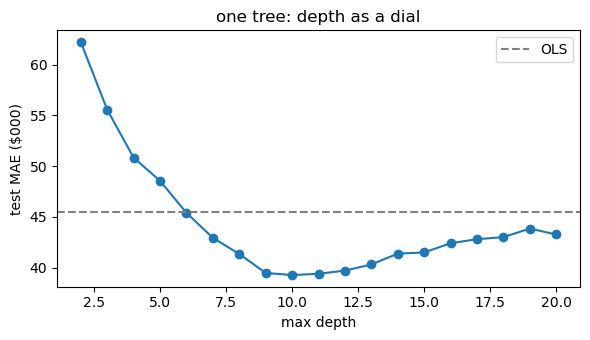

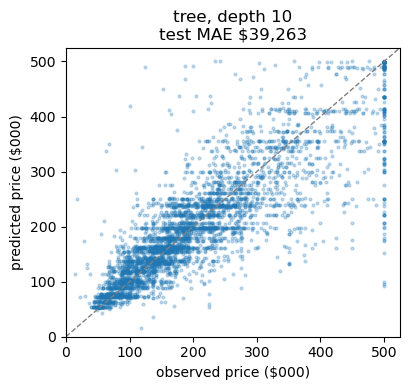

,target,test MAE ($),test RMSE ($),test R²,train R²
"OLS, raw price",price,"49,920","69,436",0.632,0.647
"OLS, log price",log price,"51,978","88,332",0.405,0.417
"OLS, log-log",log price,"45,468","68,146",0.646,0.657
"OLS, degree-2 polynomial",log price,"42,471","63,662",0.691,0.710
ridge (λ = 1),log price,"45,510","68,002",0.647,0.664
lasso (λ = 0.001),log price,"46,199","67,931",0.648,0.663
"tree, depth 2",log price,"62,249","87,465",0.416,0.427
"tree, full depth",log price,"43,924","69,430",0.632,1.000
"tree, depth 10",log price,"39,263","60,998",0.716,0.828


In [135]:
depths = range(2, 21)
Xtr, Xte = preprocess_log.fit_transform(X_train), preprocess_log.transform(X_test)        # same train/test steps as in report()
mae = [mean_absolute_error(y_test, np.exp(DecisionTreeRegressor(max_depth=d, random_state=0)
                                             .fit(Xtr, np.log(y_train)).predict(Xte))) for d in depths]
best_d = list(depths)[int(np.argmin(mae))]
plt.figure(figsize=(6, 3.5)); plt.plot(depths, np.array(mae) / 1000, marker="o")
plt.axhline(results.loc["OLS, log-log", "test MAE ($)"] / 1000, ls="--", color="gray", label="OLS")
plt.xlabel("max depth"); plt.ylabel("test MAE ($000)"); plt.title("one tree: depth as a dial"); plt.legend()
plt.tight_layout(); plt.show()
tree_best = report(f"tree, depth {best_d}", DecisionTreeRegressor(max_depth=best_d, random_state=0), prep=preprocess_log)
plot_fit(f"tree, depth {best_d}")
show()


### A tuned tree beats the line

At its best depth a single tree misses by about $39,000 — 14% less than the log-log line, with no feature engineering at all. But look at the curve: the sweet spot is narrow, and a tree that deep is a brittle object — move a few training rows and the splits change.

The fix is not a better tree. It is **many trees.**

### Random forest — many overfit trees, averaged

Two ingredients, both from the deck (slides 71–86):

1. **Bootstrap.** Draw the training rows *with replacement* — a new, slightly different dataset each time. Grow a full-depth tree on each.
2. **Random features.** At every split, let the tree choose from a random subset of the features, so the trees don't all ask the same first question.

Each tree overfits its own sample. Their errors are different, so when you **average** a few hundred of them, the overfitting averages away and the signal stays. Bagging = bootstrap + aggregate.

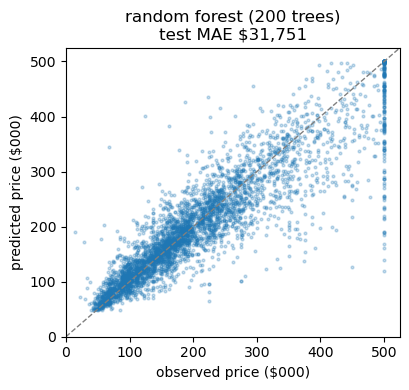

,target,test MAE ($),test RMSE ($),test R²,train R²
"OLS, raw price",price,"49,920","69,436",0.632,0.647
"OLS, log price",log price,"51,978","88,332",0.405,0.417
"OLS, log-log",log price,"45,468","68,146",0.646,0.657
"OLS, degree-2 polynomial",log price,"42,471","63,662",0.691,0.710
ridge (λ = 1),log price,"45,510","68,002",0.647,0.664
lasso (λ = 0.001),log price,"46,199","67,931",0.648,0.663
"tree, depth 2",log price,"62,249","87,465",0.416,0.427
"tree, full depth",log price,"43,924","69,430",0.632,1.000
"tree, depth 10",log price,"39,263","60,998",0.716,0.828
random forest (200 trees),log price,"31,751","51,123",0.801,0.968


In [136]:
forest = report("random forest (200 trees)", RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=0), prep=preprocess_log)
plot_fit("random forest (200 trees)")
show()


### The table changes character

One line of code and the typical miss drops from about $46,000 to about **$32,000** — 30% less error than the log-log line, and a quarter less than the polynomial, with no scaling, no tuning, and nothing the log-log step did mattering to it.

Train R² is high again — the forest still fits training data very closely — but this time the test error says it generalises. Overfitting that averages away is not overfitting.

### Boosting — the idea

A forest grows its trees *in parallel*, each ignorant of the others. Boosting grows them *in sequence*, each one correcting what the previous ones got wrong:

1. Start with a trivial prediction — the average price.
2. Compute the **residuals** — what's left unexplained.
3. Fit a *small* tree to the residuals.
4. Add a *fraction* of that tree's prediction to the running total (the fraction is the **learning rate**).
5. Repeat: new residuals, new small tree, small step. Stop when adding trees stops helping.

*(deck slides 87–97: the worked example — Tuesday we walk through the numbers)*

Small steps toward the right direction, hundreds of times. That is gradient boosting.

---
### Gradient boosting, fitted

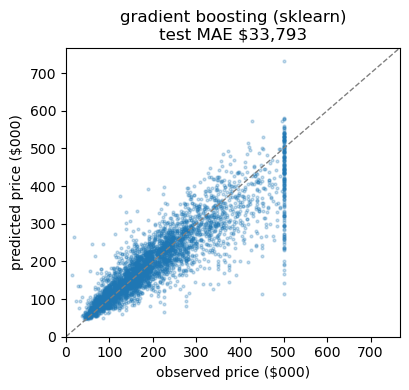

,target,test MAE ($),test RMSE ($),test R²,train R²
"OLS, raw price",price,"49,920","69,436",0.632,0.647
"OLS, log price",log price,"51,978","88,332",0.405,0.417
"OLS, log-log",log price,"45,468","68,146",0.646,0.657
"OLS, degree-2 polynomial",log price,"42,471","63,662",0.691,0.710
ridge (λ = 1),log price,"45,510","68,002",0.647,0.664
lasso (λ = 0.001),log price,"46,199","67,931",0.648,0.663
"tree, depth 2",log price,"62,249","87,465",0.416,0.427
"tree, full depth",log price,"43,924","69,430",0.632,1.000
"tree, depth 10",log price,"39,263","60,998",0.716,0.828
random forest (200 trees),log price,"31,751","51,123",0.801,0.968


In [137]:
gbr = report("gradient boosting (sklearn)", GradientBoostingRegressor(n_estimators=300, learning_rate=0.1, max_depth=3, random_state=0), prep=preprocess_log)
plot_fit("gradient boosting (sklearn)")
show()


### Watch it learn: test error against the number of trees

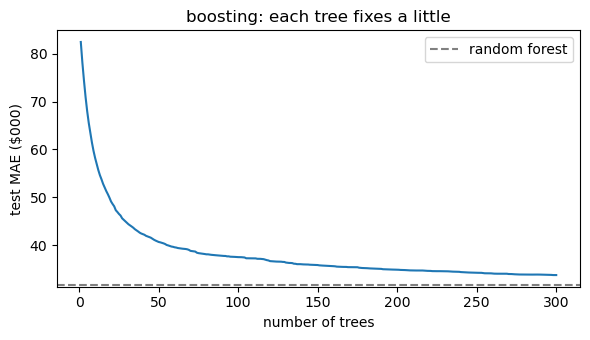

In [138]:
inner = gbr[-1]                       # the fitted booster
Xte_t = gbr[:-1].transform(X_test)    # the fitted recipe, applied to the test split
staged = [mean_absolute_error(y_test, np.exp(p)) for p in inner.staged_predict(Xte_t)]
plt.figure(figsize=(6, 3.5)); plt.plot(range(1, len(staged) + 1), np.array(staged) / 1000)
plt.axhline(results.loc["random forest (200 trees)", "test MAE ($)"] / 1000, ls="--", color="gray", label="random forest")
plt.xlabel("number of trees"); plt.ylabel("test MAE ($000)"); plt.title("boosting: each tree fixes a little"); plt.legend()
plt.tight_layout(); plt.show()

### XGBoost — the same idea, engineered

XGBoost ("extreme gradient boosting") is gradient boosting with a regularised objective, a smarter way of choosing splits, native handling of missing values, and a fast, parallel implementation. It won most tabular-data competitions for a decade and is still the default choice for structured data in industry. Scikit-learn's `HistGradientBoostingRegressor` is the same family.

Same interface: fit, predict, one row.

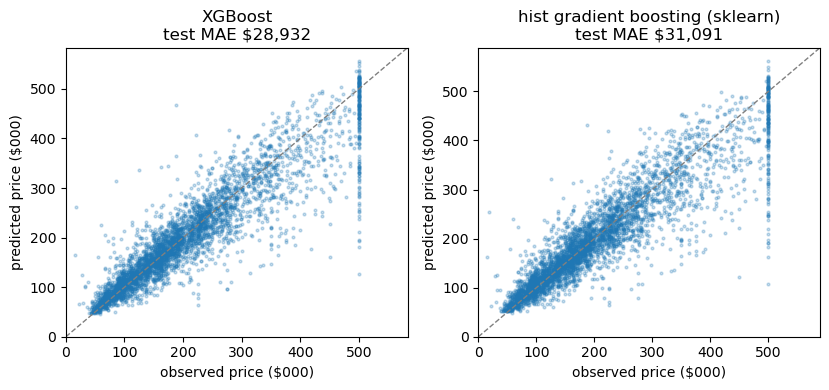

,target,test MAE ($),test RMSE ($),test R²,train R²
"OLS, raw price",price,"49,920","69,436",0.632,0.647
"OLS, log price",log price,"51,978","88,332",0.405,0.417
"OLS, log-log",log price,"45,468","68,146",0.646,0.657
"OLS, degree-2 polynomial",log price,"42,471","63,662",0.691,0.710
ridge (λ = 1),log price,"45,510","68,002",0.647,0.664
lasso (λ = 0.001),log price,"46,199","67,931",0.648,0.663
"tree, depth 2",log price,"62,249","87,465",0.416,0.427
"tree, full depth",log price,"43,924","69,430",0.632,1.000
"tree, depth 10",log price,"39,263","60,998",0.716,0.828
random forest (200 trees),log price,"31,751","51,123",0.801,0.968


In [139]:
try:
    from xgboost import XGBRegressor
except ModuleNotFoundError:          # Colab has it pre-installed; a local machine may not
    %pip install -q xgboost
    from xgboost import XGBRegressor
xgb = report("XGBoost", XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=6, subsample=0.8, random_state=0), prep=preprocess_log)
hgb = report("hist gradient boosting (sklearn)", HistGradientBoostingRegressor(random_state=0), prep=preprocess_log)
plot_fit("XGBoost", "hist gradient boosting (sklearn)")
show()


### 13 · The whole table

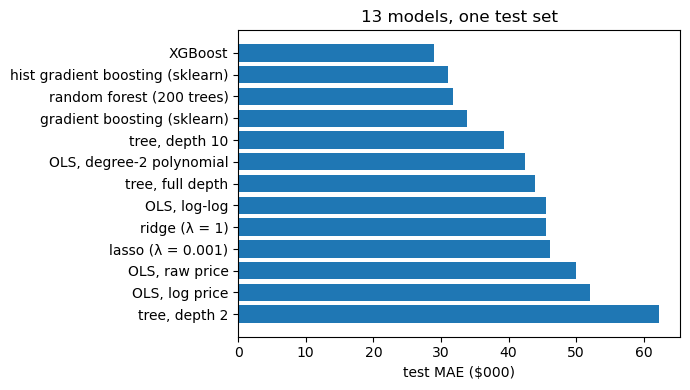

,target,test MAE ($),test RMSE ($),test R²,train R²
"OLS, raw price",price,"49,920","69,436",0.632,0.647
"OLS, log price",log price,"51,978","88,332",0.405,0.417
"OLS, log-log",log price,"45,468","68,146",0.646,0.657
"OLS, degree-2 polynomial",log price,"42,471","63,662",0.691,0.710
ridge (λ = 1),log price,"45,510","68,002",0.647,0.664
lasso (λ = 0.001),log price,"46,199","67,931",0.648,0.663
"tree, depth 2",log price,"62,249","87,465",0.416,0.427
"tree, full depth",log price,"43,924","69,430",0.632,1.000
"tree, depth 10",log price,"39,263","60,998",0.716,0.828
random forest (200 trees),log price,"31,751","51,123",0.801,0.968


In [140]:
order = results.sort_values("test MAE ($)", ascending=False)
plt.figure(figsize=(7, 4)); plt.barh(order.index, order["test MAE ($)"] / 1000)
plt.xlabel("test MAE ($000)"); plt.title(f"{len(results)} models, one test set"); plt.tight_layout(); plt.show()
show()

### Read the table

- **Every linear model misses by $42–46k. Every ensemble misses by $29–34k.** The gap is not tuning — the forest and the boosters ran on default settings.
- The ensembles never saw a scaled feature, never needed the log target, and would have run with the missing values left in. **Trees care less about the preprocessing that linear models cannot live without.**
- A single tree is worse than OLS; two hundred of them are far better. The power is in the *ensemble*, not the tree.
- Boosting and bagging land in the same place here. On other data one wins clearly; try both.

### What matters? Opening the box

A coefficient tells you what a linear model thinks. An ensemble has no coefficients. Two tools that work for *any* model:

- **Permutation importance:** shuffle one feature's column in the test set and see how much the error rises. If the model wasn't using the feature, nothing happens.
- **Partial dependence:** hold everything else fixed, sweep one feature across its range, and plot the model's average prediction. The *shape* of the relationship the model learned.

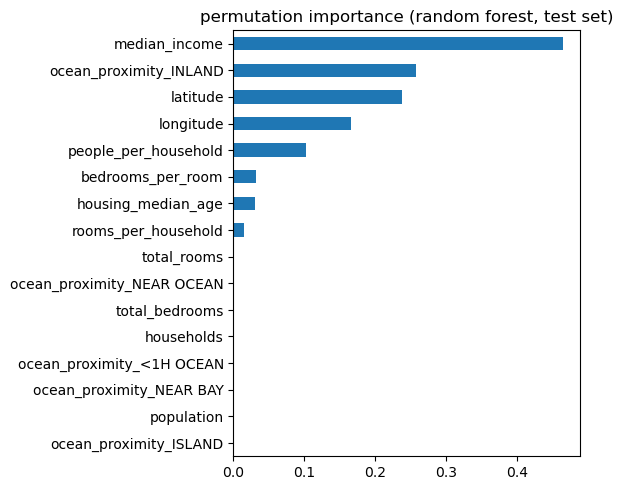

In [141]:
model = forest
Xte_t = model[:-1].transform(X_test)
pi = permutation_importance(model[-1], Xte_t, np.log(y_test), n_repeats=5, random_state=0, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=feat_names).sort_values()
imp.plot.barh(figsize=(6, 5), title="permutation importance (random forest, test set)")
plt.tight_layout(); plt.show()

### Why the line lost: location

Income is the strongest feature — the line had that. The next two are **latitude and longitude**, and that is the point: price depends on *where* you are, which is a joint function of two coordinates — a map. A line can only add a north–south slope to an east–west slope. A tree can carve the map into regions.

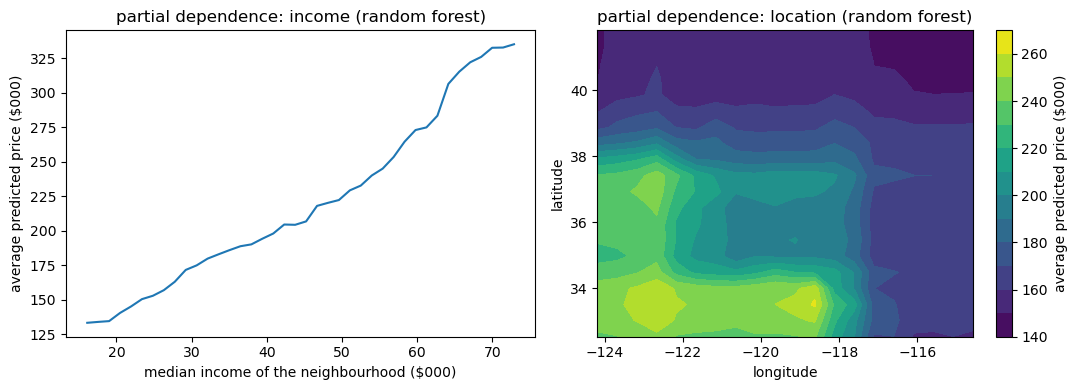

In [142]:
def partial_dependence(fitted, X, col, grid):
    """For each value on the grid: set every row's `col` to it, predict with the whole fitted pipeline, convert to dollars, average."""
    return np.array([np.exp(fitted.predict(X.assign(**{col: v}))).mean() for v in grid])

Xs = X_test.sample(800, random_state=0)                              # a sample of test neighbourhoods; everything else in each row stays as it is
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

# left: income.  The file stores income in $10,000s, so 3.0 = $30,000.
inc_grid = np.linspace(X_test.median_income.quantile(0.05), X_test.median_income.quantile(0.95), 40)
ax[0].plot(inc_grid * 10, partial_dependence(model, Xs, "median_income", inc_grid) / 1000)
ax[0].set(xlabel="median income of the neighbourhood ($000)", ylabel="average predicted price ($000)", title="partial dependence: income (random forest)")

# right: location.  A grid over the map; colour = average predicted price when a neighbourhood is placed there.
lon = np.linspace(X_test.longitude.min(), X_test.longitude.max(), 20); lat = np.linspace(X_test.latitude.min(), X_test.latitude.max(), 20)
price = np.array([[np.exp(model.predict(Xs.assign(longitude=lo, latitude=la))).mean() for lo in lon] for la in lat]) / 1000
c = ax[1].contourf(lon, lat, price, levels=12, cmap="viridis"); fig.colorbar(c, ax=ax[1], label="average predicted price ($000)")
ax[1].set(xlabel="longitude", ylabel="latitude", title="partial dependence: location (random forest)")
plt.tight_layout(); plt.show()


### The same map, from the data

The right panel above is the *model's* map. Here is the *data's*: every neighbourhood at its own coordinates, coloured by its observed price, dot size by population. No model, no fitting — just the rows. The coastline draws itself, and so do the two expensive patches the forest found.


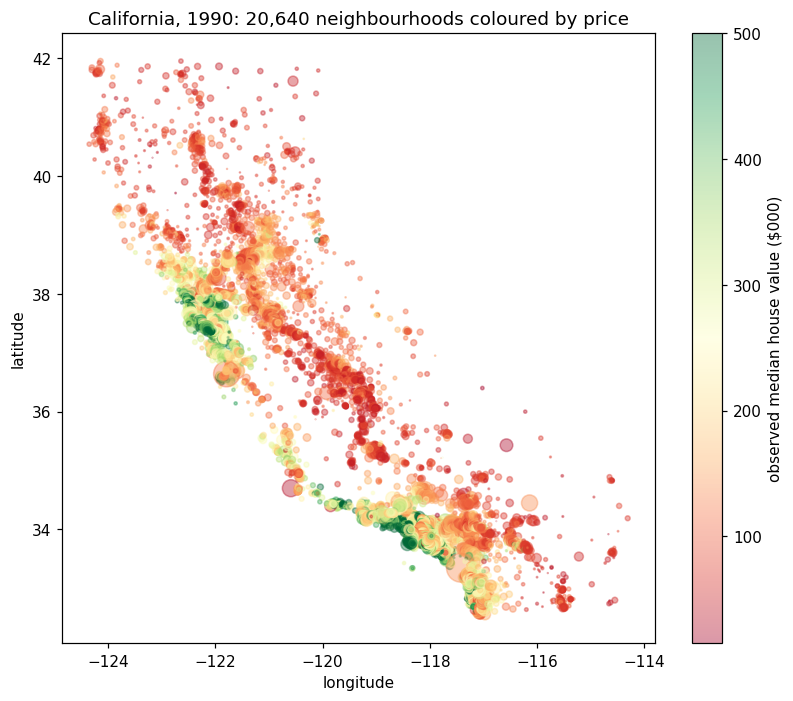

In [ ]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))
sc = ax.scatter(housing.longitude, housing.latitude,
                c=housing.median_house_value / 1000, cmap="RdYlGn",           # colour = observed price: red cheap, green expensive
                s=housing.population.fillna(housing.population.median()) / 100, alpha=0.4)   # size = population
fig.colorbar(sc, ax=ax, label="observed median house value ($000)")
ax.set(xlabel="longitude", ylabel="latitude", title="California, 1990: 20,640 neighbourhoods coloured by price")
plt.tight_layout(); plt.show()


---
## Tuning by cross-validation

Every knob we set by hand above — λ for a penalty, the depth of a tree, the number of trees in a forest — can be set by Module 2's cross-validation instead: try a grid of values, score each by 5-fold CV *inside the training split*, keep the best. The test split is never touched until the end.

### λ for the lasso

Part I picked λ by hand. `LassoCV` tries a grid of λ, scores each by cross-validation on the training split, and refits with the winner.


λ chosen by cross-validation: 0.00039


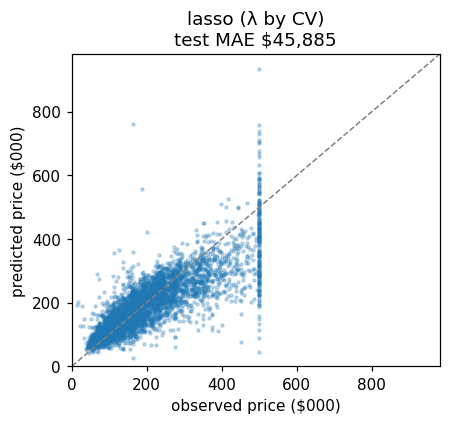

,target,test MAE ($),test RMSE ($),test R²,train R²
"OLS, raw price",price,"49,920","69,436",0.632,0.647
"OLS, log price",log price,"51,978","88,332",0.405,0.417
"OLS, log-log",log price,"45,468","68,146",0.646,0.657
"OLS, degree-2 polynomial",log price,"42,471","63,662",0.691,0.710
ridge (λ = 1),log price,"45,510","68,002",0.647,0.664
lasso (λ = 0.001),log price,"46,199","67,931",0.648,0.663
"tree, depth 2",log price,"62,249","87,465",0.416,0.427
"tree, full depth",log price,"43,924","69,430",0.632,1.000
"tree, depth 10",log price,"39,263","60,998",0.716,0.828
random forest (200 trees),log price,"31,751","51,123",0.801,0.968


In [ ]:
lasso_cv = report("lasso (λ by CV)", LassoCV(cv=5, random_state=0), prep=scaled_prep)
print("λ chosen by cross-validation:", round(lasso_cv[-1].alpha_, 5))
plot_fit("lasso (λ by CV)")
show()


### The knobs of an ensemble

Forests and boosters have knobs: number of trees, depth, learning rate, subsample fraction. `RandomizedSearchCV` tries random combinations, scores each by cross-validation on the training split, and keeps the best. It is the deck's "Part 3: cross-validation and grid search" applied to a forest. Expensive, and usually worth a few percent — never the difference between $45k and $30k.

best settings: {'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 20}


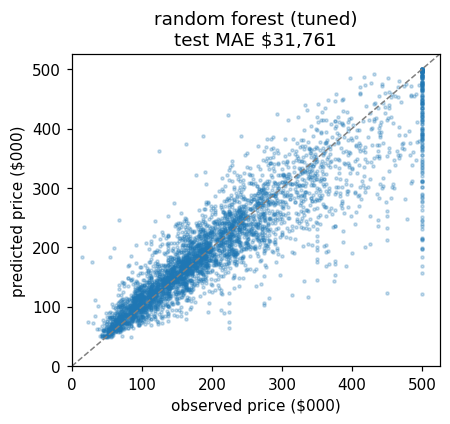

,target,test MAE ($),test RMSE ($),test R²,train R²
"OLS, raw price",price,"49,920","69,436",0.632,0.647
"OLS, log price",log price,"51,978","88,332",0.405,0.417
"OLS, log-log",log price,"45,468","68,146",0.646,0.657
"OLS, degree-2 polynomial",log price,"42,471","63,662",0.691,0.710
ridge (λ = 1),log price,"45,510","68,002",0.647,0.664
lasso (λ = 0.001),log price,"46,199","67,931",0.648,0.663
"tree, depth 2",log price,"62,249","87,465",0.416,0.427
"tree, full depth",log price,"43,924","69,430",0.632,1.000
"tree, depth 10",log price,"39,263","60,998",0.716,0.828
random forest (200 trees),log price,"31,751","51,123",0.801,0.968


In [ ]:
from sklearn.model_selection import RandomizedSearchCV
search = RandomizedSearchCV(
    RandomForestRegressor(random_state=0, n_jobs=-1),
    {"n_estimators": [100, 200, 400], "max_depth": [None, 10, 20], "min_samples_leaf": [1, 2, 5], "max_features": [0.5, 0.8, 1.0]},
    n_iter=8, cv=3, scoring="neg_mean_absolute_error", random_state=0, n_jobs=-1)
Xtr_t = preprocess_log.fit_transform(X_train)
search.fit(Xtr_t, np.log(y_train))
print("best settings:", search.best_params_)
tuned = report("random forest (tuned)", RandomForestRegressor(random_state=0, n_jobs=-1, **search.best_params_), prep=preprocess_log)
plot_fit("random forest (tuned)")
show()


### Another dataset, the opposite answer

Ames, Iowa: 1,460 house sales, 80 raw characteristics. In an earlier version of this course we spent two full sessions preprocessing it — imputing, encoding ordinal quality scales by hand, logging the skewed columns, one-hot encoding the rest. 215 model-ready features.

Fit the same models to *that*.

In [ ]:
Xa_train = pd.read_csv(f"{REPO}/X_train_ready.csv", index_col=0).drop(columns="Id")
Xa_test  = pd.read_csv(f"{REPO}/X_test_ready.csv",  index_col=0).drop(columns="Id")
ya_train = pd.read_csv(f"{REPO}/y_train.csv", index_col=0).squeeze()
ya_test  = pd.read_csv(f"{REPO}/y_test.csv",  index_col=0).squeeze()
print(Xa_train.shape, Xa_test.shape, "| median price", f"${ya_train.median():,.0f}")

ames = pd.DataFrame(columns=["test MAE ($)", "test R²"])
for name, m in [("OLS", LinearRegression()),
                ("lasso (λ by CV)", make_pipeline(StandardScaler(), LassoCV(cv=5, max_iter=5000, random_state=0))),
                ("random forest (200 trees)", RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=0)),
                ("hist gradient boosting", HistGradientBoostingRegressor(random_state=0))]:
    m.fit(Xa_train, np.log(ya_train)); p = np.exp(m.predict(Xa_test))
    ames.loc[name] = [mean_absolute_error(ya_test, p), r2_score(ya_test, p)]
show(ames)

(1168, 215) (292, 215) | median price $165,000


,test MAE ($),test R²
OLS,"14,887",0.929
lasso (λ by CV),"14,929",0.910
random forest (200 trees),"17,391",0.887
hist gradient boosting,"16,198",0.894


### Features beat algorithms — when you do the work

On Ames, **plain OLS beats the forest and the booster.** Same models, opposite verdict.

The difference is not the algorithm. It is 215 features that two sessions of human judgment built: *which* quality scales are ordinal, *which* columns to log, *what* a missing garage year means. Once the features carry the structure, a line is enough — and a line is faster, more stable, and you can read its coefficients.

- **Do nothing to the features → ensembles win big** (California: a third less error).
- **Do the work → the line catches up or wins** (Ames).

Which one you should do depends on what the prediction is for, how much time you have, and whether anyone needs to explain the model afterwards. That is a judgment, and it's yours.

### What to take away

1. **Judge a number in its own units.** MAE in dollars first; R² for comparison across datasets.
2. **Linear models need the preprocessing; trees don't.** Impute, encode, log, scale — for the line. The forest ran on the raw columns.
3. **A penalty is a prior that effects are small.** Ridge shrinks, lasso selects, and the penalty must be tuned by cross-validation on scaled features.
4. **One tree memorises. Many trees generalise.** Forests average; boosting corrects. Both beat the line by a third here with no tuning at all.
5. **Open the box with permutation importance and partial dependence.** They work for any model — and they told us *why* the line lost.
6. **Features versus algorithms is a trade-off, not a verdict.** Know which side of it your problem is on.